# Model C vs ANFIS — Held-out Test Results Comparison

## Supervisor reporting notebook

This notebook reads the frozen experiment package:

```text
model_c_anfis_supervisor_results.zip
```

and compares the held-out test performance of:

| Experiment | Stage 1 | Stage 2 |
|---|---|---|
| Baseline | RF + ROS | GBM + OBU |
| ANFIS-A | RF + ROS | ANFIS, no resampling |
| ANFIS-B | RF + ROS | ANFIS + OBU |
| ANFIS-C | Compact ANFIS + ROS | ANFIS + OBU |
| ANFIS-D | Three one-vs-rest ANFIS models | — |

It reports:

- Seed-42 results
- Five independently trained seeds: mean ± SD
- Five-seed probability ensemble
- Class-wise precision, recall and F1
- Confusion matrices
- Stage-wise results
- Paired bootstrap confidence intervals
- Exact McNemar tests
- Supervisor-ready conclusion

**This is a reporting notebook. It does not retrain or retune any model.**

# Kaggle run instructions

Attach the previous ANFIS result dataset. Kaggle may expose it in either form:

```text
A. Extracted folder:
/kaggle/input/.../anfis-results/
    08_SELECTED_CONFIGS.json
    tables/
    predictions/
    99_ARTIFACT_MANIFEST.csv
```

or:

```text
B. Original ZIP:
model_c_anfis_supervisor_results.zip
```

Recommended settings:

```text
Accelerator: None
Internet: Off
Session → Restart Session → Run All
```

The notebook automatically detects either source form.

In [1]:
from textwrap import dedent
# ============================================================
# Cell 1 — Imports and output folders
# ============================================================
import io
import json
import zipfile
import hashlib
import shutil
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
)

from IPython.display import (
    display,
    FileLink,
    Markdown,
)

RESULT_ZIP_FILENAME = (
    "model_c_anfis_supervisor_results.zip"
)

EXPERIMENT_ORDER = [
    "Baseline RF+GBM",
    "ANFIS-A RF+ANFIS no resampling",
    "ANFIS-B RF+ANFIS+OBU",
    "ANFIS-C compact ANFIS+ANFIS",
    "ANFIS-D three OVR ANFIS",
]

SHORT_NAMES = {
    "Baseline RF+GBM": "Baseline",
    "ANFIS-A RF+ANFIS no resampling": "ANFIS-A",
    "ANFIS-B RF+ANFIS+OBU": "ANFIS-B",
    "ANFIS-C compact ANFIS+ANFIS": "ANFIS-C",
    "ANFIS-D three OVR ANFIS": "ANFIS-D",
}

LABEL_ORDER = [
    "low",
    "moderate",
    "high",
]

if Path("/kaggle/working").exists():
    BASE_DIR = Path("/kaggle/working")
    ENVIRONMENT = "kaggle"
elif Path("/content").exists():
    BASE_DIR = Path("/content")
    ENVIRONMENT = "colab"
else:
    BASE_DIR = Path("/tmp")
    ENVIRONMENT = "local"

OUTPUT_DIR = (
    BASE_DIR
    / "anfis_test_comparison_report"
)

TABLE_DIR = OUTPUT_DIR / "tables"
PLOT_DIR = OUTPUT_DIR / "plots"

if OUTPUT_DIR.exists():
    shutil.rmtree(
        OUTPUT_DIR
    )

for folder in [
    OUTPUT_DIR,
    TABLE_DIR,
    PLOT_DIR,
]:
    folder.mkdir(
        parents=True,
        exist_ok=True,
    )

SEARCH_ROOTS = [
    Path("/kaggle/input"),
    Path("/kaggle/working"),
    Path("/content"),
    Path("/mnt/data"),
    Path.cwd(),
]

print(
    "Environment:",
    ENVIRONMENT,
)

print(
    "Output directory:",
    OUTPUT_DIR,
)

Environment: kaggle
Output directory: /kaggle/working/anfis_test_comparison_report


In [2]:
# ============================================================
# Cell 2 — Discover and validate the frozen result source
# Supports either:
#   A. Extracted Kaggle result directory
#   B. Original result ZIP
# ============================================================
def sha256_bytes(
    content,
):
    digest = hashlib.sha256()
    digest.update(
        content
    )
    return digest.hexdigest()


REQUIRED_RESULT_FILES = {
    "08_SELECTED_CONFIGS.json",
    "04C_BASELINE_COMPATIBILITY_REPORT.json",
    "04_DATASET_AUDIT.json",
    "99_ARTIFACT_MANIFEST.csv",
    "tables/09_TEST_SEED_METRICS_RAW.csv",
    "tables/11_TEST_SEED_SUMMARY.csv",
    "tables/12_TEST_SEED_AVERAGED_METRICS.csv",
    "tables/13_TEST_SEED_AVERAGED_STAGEWISE.csv",
    "tables/14_PAIRED_BOOTSTRAP_VS_BASELINE.csv",
    "tables/15_EXACT_MCNEMAR_VS_BASELINE.csv",
    "tables/20_SUPERVISOR_DECISION_TABLE.csv",
    "predictions/10_TEST_PREDICTIONS_ALL_SEEDS.csv",
}


def directory_missing_files(
    directory,
):
    return sorted(
        filename
        for filename
        in REQUIRED_RESULT_FILES
        if not (
            directory
            / filename
        ).is_file()
    )


def inspect_zip_candidate(
    path,
):
    report = {
        "path": str(path),
        "valid_zip": False,
        "entry_count": 0,
        "corrupt_member": None,
        "missing_required": sorted(
            REQUIRED_RESULT_FILES
        ),
        "error": None,
    }

    try:
        with zipfile.ZipFile(
            path,
            "r",
        ) as archive:
            report[
                "valid_zip"
            ] = True

            report[
                "corrupt_member"
            ] = archive.testzip()

            names = set(
                archive.namelist()
            )

            report[
                "entry_count"
            ] = len(names)

            report[
                "missing_required"
            ] = sorted(
                REQUIRED_RESULT_FILES
                - names
            )

    except (
        zipfile.BadZipFile,
        OSError,
        PermissionError,
    ) as exc:
        report[
            "error"
        ] = repr(exc)

    return report


def discover_result_source():
    # --------------------------------------------------------
    # A. Search for extracted result directories.
    # Marker file:
    # 08_SELECTED_CONFIGS.json
    # --------------------------------------------------------
    directory_candidates = []

    for root in SEARCH_ROOTS:
        if not root.exists():
            continue

        try:
            for marker in root.rglob(
                "08_SELECTED_CONFIGS.json"
            ):
                if not marker.is_file():
                    continue

                candidate = (
                    marker.parent.resolve()
                )

                if (
                    OUTPUT_DIR.resolve()
                    in candidate.parents
                    or candidate
                    == OUTPUT_DIR.resolve()
                ):
                    continue

                directory_candidates.append(
                    candidate
                )

        except (
            PermissionError,
            OSError,
        ):
            continue

    directory_candidates = sorted(
        set(
            directory_candidates
        ),
        key=lambda path: (
            len(
                str(path)
            ),
            str(path),
        ),
    )

    valid_directories = []

    if directory_candidates:
        print(
            "Extracted result-directory candidates:"
        )

        for directory in (
            directory_candidates
        ):
            missing = (
                directory_missing_files(
                    directory
                )
            )

            print(
                "\n ",
                directory,
            )

            print(
                "   Missing required files:",
                len(
                    missing
                ),
            )

            if (
                missing
                and len(
                    missing
                )
                <= 5
            ):
                print(
                    "  ",
                    missing,
                )

            if not missing:
                valid_directories.append(
                    directory
                )

    # --------------------------------------------------------
    # B. Search for original ZIP packages.
    # --------------------------------------------------------
    zip_candidates = []

    for root in SEARCH_ROOTS:
        if not root.exists():
            continue

        try:
            zip_candidates.extend(
                root.rglob(
                    "*.zip"
                )
            )

            zip_candidates.extend(
                root.rglob(
                    "*.ZIP"
                )
            )

        except (
            PermissionError,
            OSError,
        ):
            continue

    zip_candidates = sorted(
        {
            path.resolve()
            for path
            in zip_candidates
            if path.is_file()
            and OUTPUT_DIR.resolve()
            not in path.resolve().parents
        },
        key=lambda path: (
            len(
                str(path)
            ),
            str(path),
        ),
    )

    valid_zips = []

    if zip_candidates:
        print(
            "\nZIP candidates:"
        )

        for path in (
            zip_candidates
        ):
            report = (
                inspect_zip_candidate(
                    path
                )
            )

            print(
                "\n ",
                path,
            )

            print(
                "   Valid ZIP:",
                report[
                    "valid_zip"
                ],
            )

            print(
                "   Entries:",
                report[
                    "entry_count"
                ],
            )

            print(
                "   Corrupt member:",
                report[
                    "corrupt_member"
                ],
            )

            print(
                "   Missing required files:",
                len(
                    report[
                        "missing_required"
                    ]
                ),
            )

            if (
                report[
                    "valid_zip"
                ]
                and report[
                    "corrupt_member"
                ]
                is None
                and not report[
                    "missing_required"
                ]
            ):
                valid_zips.append(
                    path
                )

    # Kaggle datasets often expose uploaded ZIP contents
    # as an extracted read-only folder. Prefer that form.
    if valid_directories:
        selected = (
            valid_directories[
                0
            ]
        )

        print(
            "\nSelected extracted result directory:"
        )

        print(
            " ",
            selected,
        )

        return (
            "directory",
            selected,
        )

    if valid_zips:
        selected = (
            valid_zips[
                0
            ]
        )

        print(
            "\nSelected original result ZIP:"
        )

        print(
            " ",
            selected,
        )

        return (
            "zip",
            selected,
        )

    raise FileNotFoundError(
        "The ANFIS result source was not found.\n\n"
        "The notebook accepts either:\n"
        "1. An extracted result directory containing "
        "08_SELECTED_CONFIGS.json, tables/, predictions/, "
        "and 99_ARTIFACT_MANIFEST.csv; or\n"
        "2. The original model_c_anfis_supervisor_results.zip.\n\n"
        "The attached Kaggle input must contain the complete "
        "previous ANFIS experiment outputs."
    )


(
    RESULT_SOURCE_TYPE,
    RESULT_SOURCE_PATH,
) = discover_result_source()


def read_result_bytes(
    filename,
):
    if (
        RESULT_SOURCE_TYPE
        == "directory"
    ):
        path = (
            RESULT_SOURCE_PATH
            / filename
        )

        if not path.is_file():
            raise FileNotFoundError(
                f"Missing result file: "
                f"{path}"
            )

        return path.read_bytes()

    if (
        RESULT_SOURCE_TYPE
        == "zip"
    ):
        with zipfile.ZipFile(
            RESULT_SOURCE_PATH,
            "r",
        ) as archive:
            try:
                return archive.read(
                    filename
                )
            except KeyError as exc:
                raise FileNotFoundError(
                    "Missing ZIP member: "
                    f"{filename}"
                ) from exc

    raise RuntimeError(
        "Unsupported result source type: "
        f"{RESULT_SOURCE_TYPE}"
    )


# ------------------------------------------------------------
# Validate required files
# ------------------------------------------------------------
missing_required = []

for filename in sorted(
    REQUIRED_RESULT_FILES
):
    try:
        read_result_bytes(
            filename
        )
    except FileNotFoundError:
        missing_required.append(
            filename
        )

if missing_required:
    raise FileNotFoundError(
        "Required result files missing: "
        f"{missing_required}"
    )

# ------------------------------------------------------------
# Validate every artifact listed in the original manifest
# ------------------------------------------------------------
manifest = pd.read_csv(
    io.BytesIO(
        read_result_bytes(
            "99_ARTIFACT_MANIFEST.csv"
        )
    )
)

manifest_failures = []

for row in manifest.to_dict(
    orient="records"
):
    filename = str(
        row[
            "File"
        ]
    )

    try:
        content = (
            read_result_bytes(
                filename
            )
        )

    except FileNotFoundError:
        manifest_failures.append(
            {
                "File": filename,
                "Problem": (
                    "Missing from result source"
                ),
            }
        )
        continue

    observed_hash = (
        sha256_bytes(
            content
        )
    )

    expected_hash = str(
        row[
            "SHA256"
        ]
    )

    if (
        observed_hash
        != expected_hash
    ):
        manifest_failures.append(
            {
                "File": filename,
                "Problem": (
                    "SHA256 mismatch"
                ),
            }
        )

if manifest_failures:
    raise RuntimeError(
        "Artifact manifest validation "
        f"failed: {manifest_failures[:10]}"
    )

source_size_bytes = None
source_entry_count = None
corrupt_member = None

if (
    RESULT_SOURCE_TYPE
    == "zip"
):
    source_size_bytes = int(
        RESULT_SOURCE_PATH.stat().st_size
    )

    with zipfile.ZipFile(
        RESULT_SOURCE_PATH,
        "r",
    ) as archive:
        source_entry_count = int(
            len(
                archive.namelist()
            )
        )

        corrupt_member = (
            archive.testzip()
        )

else:
    source_files = [
        path
        for path
        in RESULT_SOURCE_PATH.rglob("*")
        if path.is_file()
    ]

    source_entry_count = int(
        len(
            source_files
        )
    )

    source_size_bytes = int(
        sum(
            path.stat().st_size
            for path
            in source_files
        )
    )

source_audit = {
    "result_source_type": (
        RESULT_SOURCE_TYPE
    ),
    "result_source_path": str(
        RESULT_SOURCE_PATH
    ),
    "source_size_bytes": (
        source_size_bytes
    ),
    "source_entry_count": (
        source_entry_count
    ),
    "manifest_rows": int(
        len(
            manifest
        )
    ),
    "manifest_failures": int(
        len(
            manifest_failures
        )
    ),
    "corrupt_member": (
        corrupt_member
    ),
}

display(
    pd.DataFrame(
        [
            source_audit
        ]
    )
)

(
    OUTPUT_DIR
    / "00_RESULT_SOURCE_AUDIT.json"
).write_text(
    json.dumps(
        source_audit,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    "Result source integrity audit: PASS"
)

Extracted result-directory candidates:

  /kaggle/input/datasets/muhammadsakibsami/anfis-results
   Missing required files: 0

Selected extracted result directory:
  /kaggle/input/datasets/muhammadsakibsami/anfis-results


,result_source_type,result_source_path,source_size_bytes,source_entry_count,manifest_rows,manifest_failures,corrupt_member
0,directory,/kaggle/input/datasets/muhammadsakibsami/anfis...,4906656,152,151,0,None


Result source integrity audit: PASS


In [3]:
# ============================================================
# Cell 3 — Load all frozen result tables
# Works with an extracted directory or a ZIP source
# ============================================================
def read_csv_from_source(
    filename,
):
    return pd.read_csv(
        io.BytesIO(
            read_result_bytes(
                filename
            )
        )
    )


def read_json_from_source(
    filename,
):
    return json.loads(
        read_result_bytes(
            filename
        )
    )


selected_configs = (
    read_json_from_source(
        "08_SELECTED_CONFIGS.json"
    )
)

baseline_compatibility = (
    read_json_from_source(
        "04C_BASELINE_COMPATIBILITY_REPORT.json"
    )
)

dataset_audit = (
    read_json_from_source(
        "04_DATASET_AUDIT.json"
    )
)

seed_metrics = (
    read_csv_from_source(
        "tables/09_TEST_SEED_METRICS_RAW.csv"
    )
)

seed_summary = (
    read_csv_from_source(
        "tables/11_TEST_SEED_SUMMARY.csv"
    )
)

ensemble_metrics = (
    read_csv_from_source(
        "tables/12_TEST_SEED_AVERAGED_METRICS.csv"
    )
)

stagewise_metrics = (
    read_csv_from_source(
        "tables/13_TEST_SEED_AVERAGED_STAGEWISE.csv"
    )
)

bootstrap_results = (
    read_csv_from_source(
        "tables/14_PAIRED_BOOTSTRAP_VS_BASELINE.csv"
    )
)

mcnemar_results = (
    read_csv_from_source(
        "tables/15_EXACT_MCNEMAR_VS_BASELINE.csv"
    )
)

decision_original = (
    read_csv_from_source(
        "tables/20_SUPERVISOR_DECISION_TABLE.csv"
    )
)

predictions_all_seeds = (
    read_csv_from_source(
        "predictions/10_TEST_PREDICTIONS_ALL_SEEDS.csv"
    )
)

print(
    "Result source type:",
    RESULT_SOURCE_TYPE,
)

print(
    "Result source path:",
    RESULT_SOURCE_PATH,
)

print(
    "Seeds:",
    sorted(
        seed_metrics[
            "Seed"
        ].unique()
    ),
)

print(
    "Test N:",
    int(
        ensemble_metrics[
            "n"
        ].iloc[0]
    ),
)

print(
    "Baseline compatibility signature:",
    baseline_compatibility.get(
        "matched_signature"
    ),
)

Result source type: directory
Result source path: /kaggle/input/datasets/muhammadsakibsami/anfis-results
Seeds: [np.int64(42), np.int64(52), np.int64(62), np.int64(72), np.int64(82)]
Test N: 833
Baseline compatibility signature: kaggle_numerical_compatible


In [4]:
# ============================================================
# Cell 4 — Selected architecture comparison
# ============================================================
architecture_rows = []

for experiment in (
    EXPERIMENT_ORDER
):
    config = (
        selected_configs[
            experiment
        ]
    )

    if experiment == (
        "Baseline RF+GBM"
    ):
        row = {
            "Experiment": "Baseline",
            "Stage 1": "13-feature RF + ROS",
            "Stage 2": "6-feature GBM + OBU",
            "Stage-1 threshold": (
                config[
                    "stage1_threshold"
                ]
            ),
            "Stage-2 threshold": (
                config[
                    "stage2_threshold"
                ]
            ),
            "Rules": "—",
            "Consequent": "—",
            "Parameter count": "Not reported",
            "Validation safety pass": True,
        }

    elif experiment == (
        "ANFIS-A RF+ANFIS no resampling"
    ):
        row = {
            "Experiment": "ANFIS-A",
            "Stage 1": "13-feature RF + ROS",
            "Stage 2": (
                "6-feature ANFIS, no resampling"
            ),
            "Stage-1 threshold": (
                config[
                    "Stage-1 threshold"
                ]
            ),
            "Stage-2 threshold": (
                config[
                    "Stage-2 threshold"
                ]
            ),
            "Rules": config[
                "Rules"
            ],
            "Consequent": config[
                "Consequent"
            ],
            "Parameter count": config[
                "Parameter count"
            ],
            "Validation safety pass": (
                config[
                    "Safety pass"
                ]
            ),
        }

    elif experiment == (
        "ANFIS-B RF+ANFIS+OBU"
    ):
        row = {
            "Experiment": "ANFIS-B",
            "Stage 1": "13-feature RF + ROS",
            "Stage 2": (
                "6-feature ANFIS + OBU"
            ),
            "Stage-1 threshold": (
                config[
                    "Stage-1 threshold"
                ]
            ),
            "Stage-2 threshold": (
                config[
                    "Stage-2 threshold"
                ]
            ),
            "Rules": config[
                "Rules"
            ],
            "Consequent": config[
                "Consequent"
            ],
            "Parameter count": config[
                "Parameter count"
            ],
            "Validation safety pass": (
                config[
                    "Safety pass"
                ]
            ),
        }

    elif experiment == (
        "ANFIS-C compact ANFIS+ANFIS"
    ):
        row = {
            "Experiment": "ANFIS-C",
            "Stage 1": (
                "7-feature compact ANFIS + ROS"
            ),
            "Stage 2": (
                "6-feature ANFIS + OBU"
            ),
            "Stage-1 threshold": (
                config[
                    "Stage-1 threshold"
                ]
            ),
            "Stage-2 threshold": (
                config[
                    "Stage-2 threshold"
                ]
            ),
            "Rules": (
                f"{config['Stage-1 rules']} "
                f"+ {config['Stage-2 rules']}"
            ),
            "Consequent": (
                f"{config['Stage-1 consequent']} "
                f"+ {config['Stage-2 consequent']}"
            ),
            "Parameter count": config[
                "Parameter count"
            ],
            "Validation safety pass": (
                config[
                    "Safety pass"
                ]
            ),
        }

    else:
        row = {
            "Experiment": "ANFIS-D",
            "Stage 1": (
                "Three 14-feature OVR ANFIS"
            ),
            "Stage 2": "—",
            "Stage-1 threshold": "Argmax",
            "Stage-2 threshold": "—",
            "Rules": (
                f"{config['Rules per classifier']} "
                "per classifier"
            ),
            "Consequent": config[
                "Consequent"
            ],
            "Parameter count": config[
                "Parameter count"
            ],
            "Validation safety pass": (
                config[
                    "Safety pass"
                ]
            ),
        }

    architecture_rows.append(
        row
    )

architecture_table = pd.DataFrame(
    architecture_rows
)

display(
    architecture_table
)

architecture_table.to_csv(
    TABLE_DIR
    / "01_EXPERIMENT_ARCHITECTURE.csv",
    index=False,
)

,Experiment,Stage 1,Stage 2,Stage-1 threshold,Stage-2 threshold,Rules,Consequent,Parameter count,Validation safety pass
0,Baseline,13-feature RF + ROS,6-feature GBM + OBU,0.44,0.5,—,—,Not reported,True
1,ANFIS-A,13-feature RF + ROS,"6-feature ANFIS, no resampling",0.44,0.24,7,first,133,True
2,ANFIS-B,13-feature RF + ROS,6-feature ANFIS + OBU,0.44,0.32,7,zero,91,True
3,ANFIS-C,7-feature compact ANFIS + ROS,6-feature ANFIS + OBU,0.48,0.3,5 + 7,first + zero,110,True
4,ANFIS-D,Three 14-feature OVR ANFIS,—,Argmax,—,3 per classifier,zero,261,False


# Two different five-seed results

## Five-seed mean ± SD

Each seed is an independent fitted model. This measures **single-model stability**.

## Five-seed probability ensemble

Probabilities from all five models are averaged before prediction. This measures **ensemble deployment performance**.

These two views are different and must be reported separately.

In [5]:
# ============================================================
# Cell 5 — Seed-42 held-out test result
# ============================================================
seed42 = (
    seed_metrics.loc[
        seed_metrics[
            "Seed"
        ].eq(42)
    ]
    .copy()
)

seed42[
    "Experiment"
] = (
    seed42[
        "Experiment"
    ]
    .map(
        SHORT_NAMES
    )
)

seed42_columns = [
    "Experiment",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "low_recall",
    "moderate_recall",
    "high_recall",
    "high_to_low",
    "low_to_high",
    "mcc",
    "qwk",
    "roc_auc_macro",
    "pr_auc_macro",
    "log_loss",
    "brier",
]

seed42_table = (
    seed42[
        seed42_columns
    ]
    .reset_index(
        drop=True
    )
)

display(
    seed42_table.round(6)
)

seed42_table.to_csv(
    TABLE_DIR
    / "02_SEED42_TEST_COMPARISON.csv",
    index=False,
)

,Experiment,accuracy,balanced_accuracy,macro_f1,low_recall,moderate_recall,high_recall,high_to_low,low_to_high,mcc,qwk,roc_auc_macro,pr_auc_macro,log_loss,brier
0,Baseline,0.721489,0.662384,0.557701,0.755072,0.495238,0.736842,2,24,0.356186,0.487260,0.785430,0.575963,0.583603,0.324746
1,ANFIS-A,0.720288,0.664807,0.542843,0.755072,0.476190,0.763158,2,38,0.355322,0.455421,0.809660,0.560765,0.574445,0.329949
2,ANFIS-B,0.715486,0.652109,0.529967,0.755072,0.438095,0.763158,2,39,0.343574,0.455399,0.812204,0.553991,0.588103,0.317450
3,ANFIS-C,0.645858,0.602771,0.451839,0.685507,0.333333,0.789474,2,86,0.265169,0.331663,0.785456,0.533954,0.613230,0.334605
4,ANFIS-D,0.650660,0.521267,0.361113,0.736232,0.038095,0.789474,4,168,0.211094,0.237539,0.716853,0.408678,0.952242,0.556051


In [6]:
# ============================================================
# Cell 6 — Five independent seeds: mean ± SD
# ============================================================
five_seed_columns = [
    "Experiment",
    "accuracy mean",
    "accuracy SD",
    "balanced_accuracy mean",
    "balanced_accuracy SD",
    "macro_f1 mean",
    "macro_f1 SD",
    "low_recall mean",
    "moderate_recall mean",
    "high_recall mean",
    "high_recall SD",
    "high_to_low mean",
    "low_to_high mean",
    "roc_auc_macro mean",
    "pr_auc_macro mean",
    "log_loss mean",
    "brier mean",
]

five_seed_table = (
    seed_summary[
        five_seed_columns
    ]
    .copy()
)

five_seed_table[
    "Experiment"
] = (
    five_seed_table[
        "Experiment"
    ]
    .map(
        SHORT_NAMES
    )
)

display(
    five_seed_table.round(6)
)

five_seed_table.to_csv(
    TABLE_DIR
    / "03_FIVE_SEED_MEAN_SD.csv",
    index=False,
)

,Experiment,accuracy mean,accuracy SD,balanced_accuracy mean,balanced_accuracy SD,macro_f1 mean,macro_f1 SD,low_recall mean,moderate_recall mean,high_recall mean,high_recall SD,high_to_low mean,low_to_high mean,roc_auc_macro mean,pr_auc_macro mean,log_loss mean,brier mean
0,Baseline,0.705402,0.012890,0.647665,0.011208,0.543253,0.011824,0.737681,0.489524,0.715789,0.011769,2.2,25.0,0.781445,0.571400,0.591964,0.330528
1,ANFIS-A,0.703721,0.012166,0.636504,0.021477,0.527225,0.014115,0.737681,0.487619,0.684211,0.064460,2.2,35.4,0.811907,0.562551,0.584900,0.333900
2,ANFIS-B,0.691236,0.031378,0.628116,0.042933,0.487139,0.082592,0.737681,0.346667,0.800000,0.084457,2.2,69.8,0.810189,0.556313,0.594699,0.322153
3,ANFIS-C,0.645858,0.040221,0.592844,0.031709,0.432768,0.062420,0.695072,0.257143,0.826316,0.088462,2.4,106.2,0.781812,0.541321,0.625338,0.343011
4,ANFIS-D,0.635534,0.021062,0.518410,0.011614,0.357507,0.016854,0.716232,0.049524,0.789474,0.000000,4.6,167.0,0.722214,0.413616,0.953262,0.558200


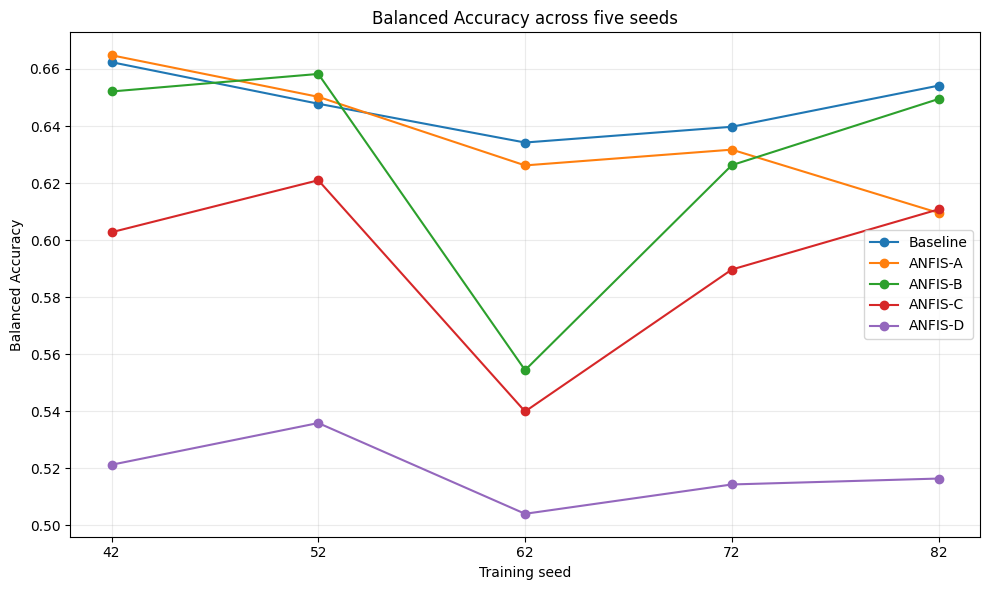

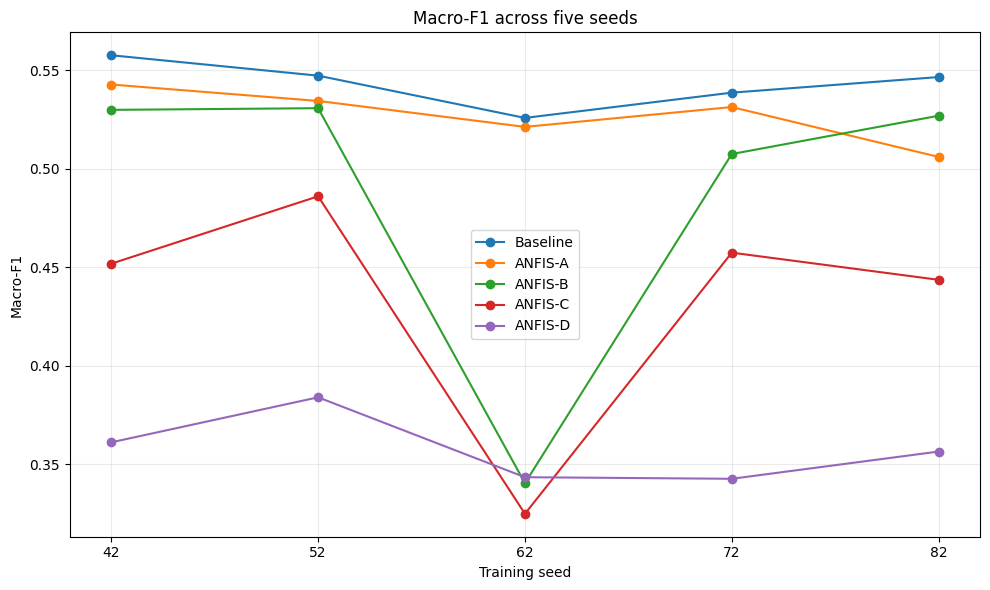

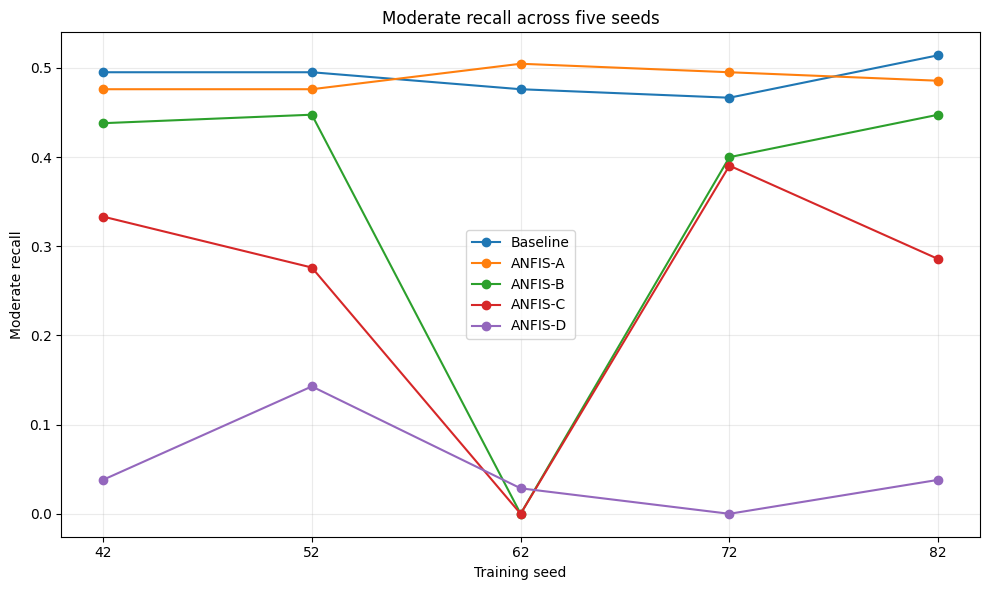

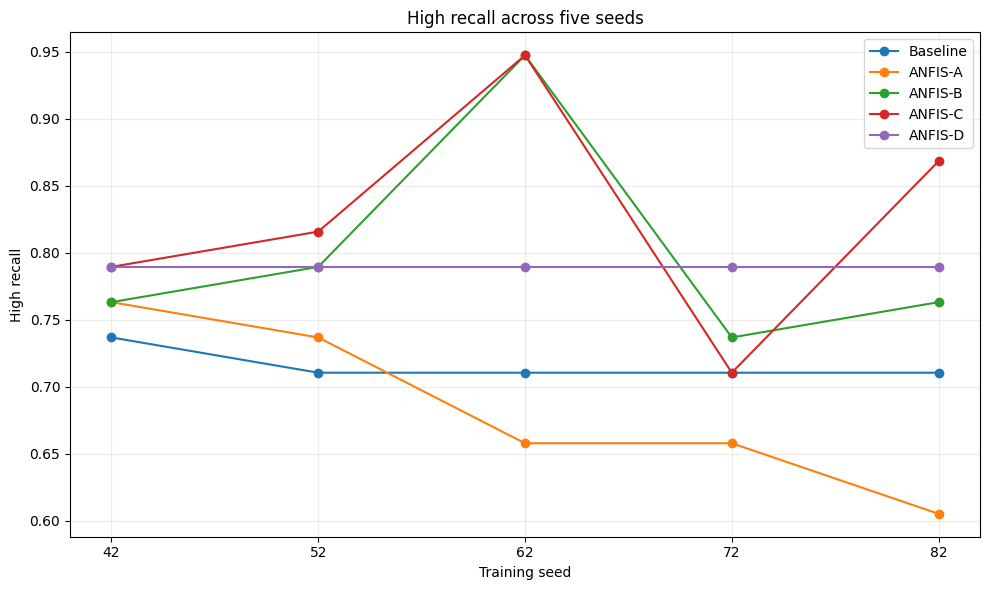

In [7]:
# ============================================================
# Cell 7 — Per-seed stability plots
# ============================================================
plot_data = (
    seed_metrics.copy()
)

plot_data[
    "Short"
] = (
    plot_data[
        "Experiment"
    ]
    .map(
        SHORT_NAMES
    )
)

for metric, title, ylabel in [
    (
        "balanced_accuracy",
        "Balanced Accuracy across five seeds",
        "Balanced Accuracy",
    ),
    (
        "macro_f1",
        "Macro-F1 across five seeds",
        "Macro-F1",
    ),
    (
        "moderate_recall",
        "Moderate recall across five seeds",
        "Moderate recall",
    ),
    (
        "high_recall",
        "High recall across five seeds",
        "High recall",
    ),
]:
    plt.figure(
        figsize=(
            10,
            6,
        )
    )

    for experiment in (
        EXPERIMENT_ORDER
    ):
        group = (
            plot_data.loc[
                plot_data[
                    "Experiment"
                ].eq(
                    experiment
                )
            ]
            .sort_values(
                "Seed"
            )
        )

        plt.plot(
            group[
                "Seed"
            ],
            group[
                metric
            ],
            marker="o",
            label=(
                SHORT_NAMES[
                    experiment
                ]
            ),
        )

    plt.xlabel(
        "Training seed"
    )

    plt.ylabel(
        ylabel
    )

    plt.title(
        title
    )

    plt.xticks(
        sorted(
            plot_data[
                "Seed"
            ].unique()
        )
    )

    plt.grid(
        alpha=0.25
    )

    plt.legend()
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / f"stability_{metric}.png",
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

,Experiment,accuracy,balanced_accuracy,macro_f1,weighted_f1,low_recall,moderate_recall,high_recall,low_precision,moderate_precision,...,moderate_f1,high_f1,high_to_low,low_to_high,mcc,qwk,roc_auc_macro,pr_auc_macro,log_loss,brier
0,Baseline,0.704682,0.647332,0.543157,0.746240,0.736232,0.495238,0.710526,0.939002,0.238532,...,0.321981,0.482143,2,25,0.336516,0.465639,0.783077,0.571849,0.590683,0.329631
1,ANFIS-A,0.707083,0.659279,0.541912,0.747324,0.736232,0.504762,0.736842,0.939002,0.253589,...,0.337580,0.462810,2,34,0.343805,0.445700,0.815648,0.560910,0.581756,0.332092
2,ANFIS-B,0.690276,0.620432,0.490322,0.734943,0.736232,0.361905,0.763158,0.939002,0.217143,...,0.271429,0.374194,2,52,0.306112,0.418491,0.813988,0.559643,0.592157,0.319921
3,ANFIS-C,0.637455,0.605416,0.437192,0.693633,0.681159,0.266667,0.868421,0.932540,0.185430,...,0.218750,0.305556,2,100,0.255758,0.324197,0.790077,0.547803,0.621089,0.339425
4,ANFIS-D,0.642257,0.517885,0.357878,0.685208,0.726087,0.038095,0.789474,0.907609,0.133333,...,0.059259,0.207612,4,167,0.201550,0.234766,0.760035,0.434261,0.950947,0.556976


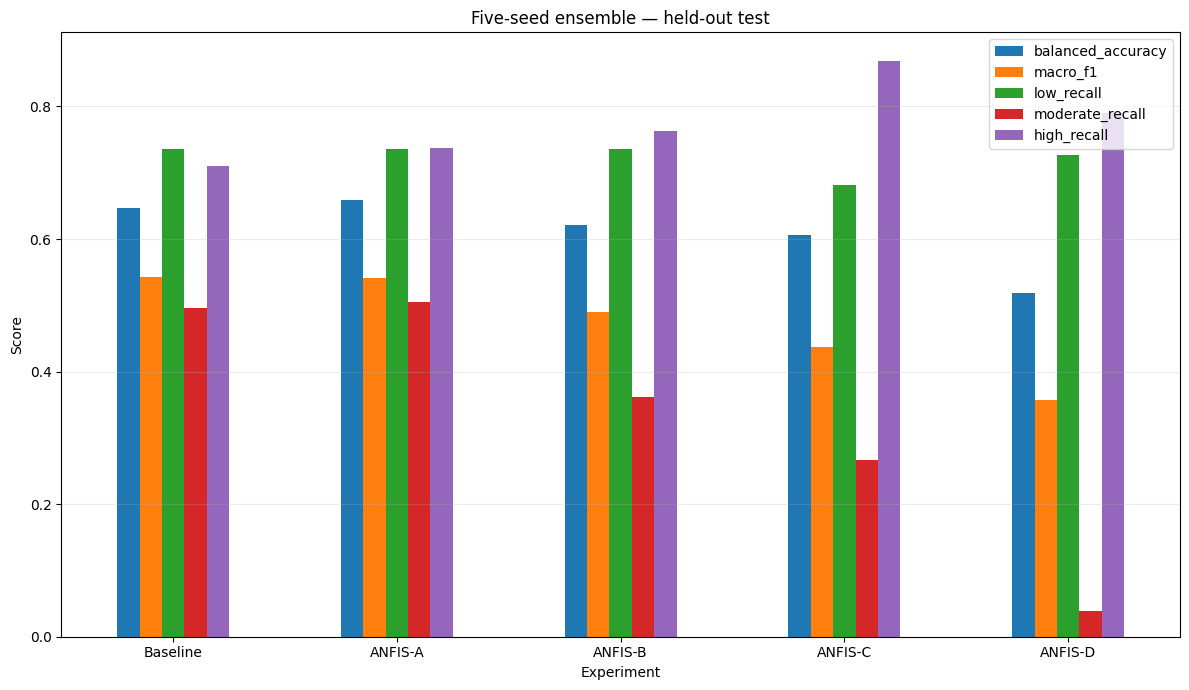

In [8]:
# ============================================================
# Cell 8 — Five-seed probability ensemble
# ============================================================
ensemble_columns = [
    "Experiment",
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "weighted_f1",
    "low_recall",
    "moderate_recall",
    "high_recall",
    "low_precision",
    "moderate_precision",
    "high_precision",
    "low_f1",
    "moderate_f1",
    "high_f1",
    "high_to_low",
    "low_to_high",
    "mcc",
    "qwk",
    "roc_auc_macro",
    "pr_auc_macro",
    "log_loss",
    "brier",
]

ensemble_table = (
    ensemble_metrics[
        ensemble_columns
    ]
    .copy()
)

ensemble_table[
    "Experiment"
] = (
    ensemble_table[
        "Experiment"
    ]
    .map(
        SHORT_NAMES
    )
)

display(
    ensemble_table.round(6)
)

ensemble_table.to_csv(
    TABLE_DIR
    / "04_FIVE_SEED_ENSEMBLE_METRICS.csv",
    index=False,
)

main_metrics = (
    ensemble_table.set_index(
        "Experiment"
    )[
        [
            "balanced_accuracy",
            "macro_f1",
            "low_recall",
            "moderate_recall",
            "high_recall",
        ]
    ]
)

main_metrics.plot(
    kind="bar",
    figsize=(
        12,
        7,
    ),
    rot=0,
)

plt.ylabel(
    "Score"
)

plt.title(
    "Five-seed ensemble — held-out test"
)

plt.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR
    / "ensemble_main_metrics.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

In [9]:
# ============================================================
# Cell 9 — Ensemble delta versus baseline
# ============================================================
baseline_row = (
    ensemble_metrics.loc[
        ensemble_metrics[
            "Experiment"
        ].eq(
            "Baseline RF+GBM"
        )
    ]
    .iloc[0]
)

delta_metrics = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "low_recall",
    "moderate_recall",
    "high_recall",
    "high_to_low",
    "low_to_high",
    "mcc",
    "qwk",
    "roc_auc_macro",
    "pr_auc_macro",
    "log_loss",
    "brier",
]

delta_rows = []

for _, row in (
    ensemble_metrics.iterrows()
):
    experiment = (
        row[
            "Experiment"
        ]
    )

    if experiment == (
        "Baseline RF+GBM"
    ):
        continue

    delta_row = {
        "Experiment": (
            SHORT_NAMES[
                experiment
            ]
        )
    }

    for metric in (
        delta_metrics
    ):
        delta_row[
            f"Delta {metric}"
        ] = (
            float(
                row[
                    metric
                ]
            )
            - float(
                baseline_row[
                    metric
                ]
            )
        )

    delta_rows.append(
        delta_row
    )

delta_table = pd.DataFrame(
    delta_rows
)

display(
    delta_table.round(6)
)

delta_table.to_csv(
    TABLE_DIR
    / "05_ENSEMBLE_DELTAS_VS_BASELINE.csv",
    index=False,
)

print(
    "For log loss, Brier, High→Low and Low→High, "
    "negative deltas are generally preferable."
)

,Experiment,Delta accuracy,Delta balanced_accuracy,Delta macro_f1,Delta low_recall,Delta moderate_recall,Delta high_recall,Delta high_to_low,Delta low_to_high,Delta mcc,Delta qwk,Delta roc_auc_macro,Delta pr_auc_macro,Delta log_loss,Delta brier
0,ANFIS-A,0.002401,0.011947,-0.001245,0.000000,0.009524,0.026316,0.0,9.0,0.007288,-0.019939,0.032571,-0.010938,-0.008927,0.002461
1,ANFIS-B,-0.014406,-0.026901,-0.052834,0.000000,-0.133333,0.052632,0.0,27.0,-0.030404,-0.047148,0.030911,-0.012206,0.001475,-0.009710
2,ANFIS-C,-0.067227,-0.041916,-0.105965,-0.055072,-0.228571,0.157895,0.0,75.0,-0.080758,-0.141442,0.007001,-0.024045,0.030407,0.009794
3,ANFIS-D,-0.062425,-0.129447,-0.185278,-0.010145,-0.457143,0.078947,2.0,142.0,-0.134967,-0.230873,-0.023042,-0.137588,0.360264,0.227345


For log loss, Brier, High→Low and Low→High, negative deltas are generally preferable.


In [10]:
# ============================================================
# Cell 10 — Reconstruct ensemble predictions and audit
# ============================================================
thresholds = {}

for experiment in (
    EXPERIMENT_ORDER
):
    config = (
        selected_configs[
            experiment
        ]
    )

    if experiment == (
        "Baseline RF+GBM"
    ):
        thresholds[
            experiment
        ] = (
            float(
                config[
                    "stage1_threshold"
                ]
            ),
            float(
                config[
                    "stage2_threshold"
                ]
            ),
        )

    elif experiment != (
        "ANFIS-D three OVR ANFIS"
    ):
        thresholds[
            experiment
        ] = (
            float(
                config[
                    "Stage-1 threshold"
                ]
            ),
            float(
                config[
                    "Stage-2 threshold"
                ]
            ),
        )

ensemble_prediction_rows = []
confusion_matrices = {}

for experiment in (
    EXPERIMENT_ORDER
):
    group = (
        predictions_all_seeds.loc[
            predictions_all_seeds[
                "Experiment"
            ].eq(
                experiment
            )
        ]
        .copy()
    )

    average_frame = (
        group.groupby(
            [
                "Row",
                "Actual",
            ],
            as_index=False,
        )[
            [
                "P_low",
                "P_moderate",
                "P_high",
                "P_stage1_at_risk",
                "P_stage2_high",
            ]
        ]
        .mean()
        .sort_values(
            "Row"
        )
        .reset_index(
            drop=True
        )
    )

    if experiment == (
        "ANFIS-D three OVR ANFIS"
    ):
        probability_matrix = (
            average_frame[
                [
                    "P_low",
                    "P_moderate",
                    "P_high",
                ]
            ]
            .to_numpy()
        )

        predicted = np.asarray(
            [
                LABEL_ORDER[
                    index
                ]
                for index
                in np.argmax(
                    probability_matrix,
                    axis=1,
                )
            ],
            dtype=object,
        )

    else:
        (
            stage1_threshold,
            stage2_threshold,
        ) = thresholds[
            experiment
        ]

        p_stage1 = (
            average_frame[
                "P_stage1_at_risk"
            ]
            .to_numpy()
        )

        p_stage2 = (
            average_frame[
                "P_stage2_high"
            ]
            .to_numpy()
        )

        predicted = np.full(
            len(
                average_frame
            ),
            "low",
            dtype=object,
        )

        at_risk = (
            p_stage1
            >= stage1_threshold
        )

        predicted[
            at_risk
        ] = np.where(
            p_stage2[
                at_risk
            ]
            >= stage2_threshold,
            "high",
            "moderate",
        )

    actual = (
        average_frame[
            "Actual"
        ]
        .astype(str)
        .to_numpy()
    )

    matrix = confusion_matrix(
        actual,
        predicted,
        labels=LABEL_ORDER,
    )

    confusion_matrices[
        experiment
    ] = matrix

    for row_index in range(
        len(
            average_frame
        )
    ):
        ensemble_prediction_rows.append(
            {
                "Experiment": experiment,
                "Row": int(
                    average_frame.loc[
                        row_index,
                        "Row",
                    ]
                ),
                "Actual": actual[
                    row_index
                ],
                "Prediction": predicted[
                    row_index
                ],
            }
        )

reconstructed_predictions = (
    pd.DataFrame(
        ensemble_prediction_rows
    )
)

audit_rows = []

for experiment in (
    EXPERIMENT_ORDER
):
    group = (
        reconstructed_predictions.loc[
            reconstructed_predictions[
                "Experiment"
            ].eq(
                experiment
            )
        ]
    )

    observed_accuracy = (
        accuracy_score(
            group[
                "Actual"
            ],
            group[
                "Prediction"
            ],
        )
    )

    observed_ba = (
        balanced_accuracy_score(
            group[
                "Actual"
            ],
            group[
                "Prediction"
            ],
        )
    )

    expected = (
        ensemble_metrics.loc[
            ensemble_metrics[
                "Experiment"
            ].eq(
                experiment
            )
        ]
        .iloc[0]
    )

    audit_rows.append(
        {
            "Experiment": (
                SHORT_NAMES[
                    experiment
                ]
            ),
            "Observed accuracy": (
                observed_accuracy
            ),
            "Expected accuracy": float(
                expected[
                    "accuracy"
                ]
            ),
            "Accuracy pass": (
                round(
                    observed_accuracy,
                    12,
                )
                == round(
                    float(
                        expected[
                            "accuracy"
                        ]
                    ),
                    12,
                )
            ),
            "Observed BA": (
                observed_ba
            ),
            "Expected BA": float(
                expected[
                    "balanced_accuracy"
                ]
            ),
            "BA pass": (
                round(
                    observed_ba,
                    12,
                )
                == round(
                    float(
                        expected[
                            "balanced_accuracy"
                        ]
                    ),
                    12,
                )
            ),
        }
    )

reconstruction_audit = (
    pd.DataFrame(
        audit_rows
    )
)

display(
    reconstruction_audit.round(12)
)

reconstruction_audit.to_csv(
    TABLE_DIR
    / "06_ENSEMBLE_RECONSTRUCTION_AUDIT.csv",
    index=False,
)

if not (
    reconstruction_audit[
        [
            "Accuracy pass",
            "BA pass",
        ]
    ]
    .all()
    .all()
):
    raise RuntimeError(
        "Reconstructed ensemble results "
        "did not match the frozen tables."
    )

print(
    "Five-seed ensemble reconstruction audit: PASS"
)

,Experiment,Observed accuracy,Expected accuracy,Accuracy pass,Observed BA,Expected BA,BA pass
0,Baseline,0.704682,0.704682,True,0.647332,0.647332,True
1,ANFIS-A,0.707083,0.707083,True,0.659279,0.659279,True
2,ANFIS-B,0.690276,0.690276,True,0.620432,0.620432,True
3,ANFIS-C,0.637455,0.637455,True,0.605416,0.605416,True
4,ANFIS-D,0.642257,0.642257,True,0.517885,0.517885,True


Five-seed ensemble reconstruction audit: PASS


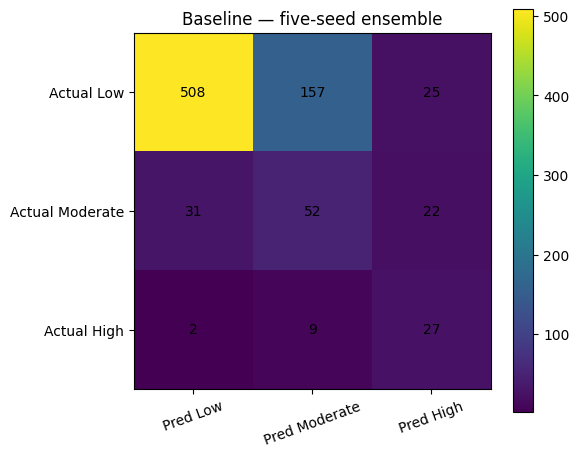

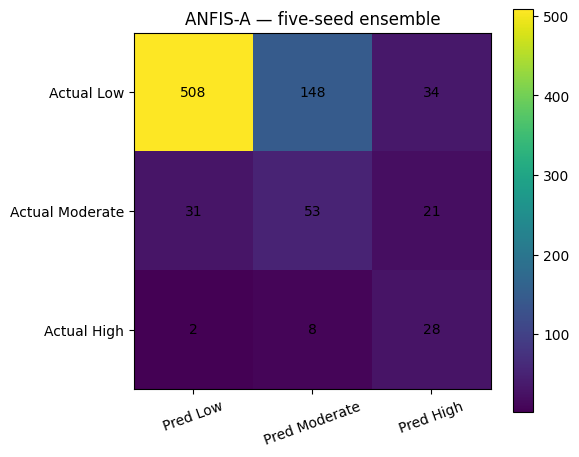

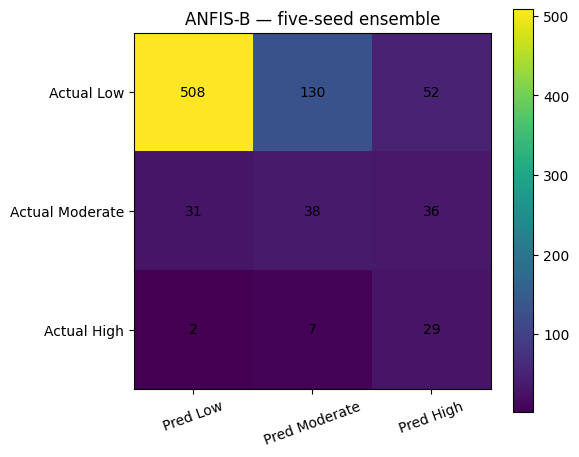

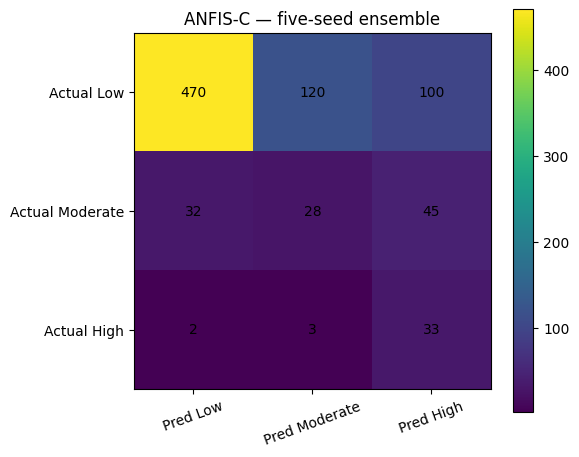

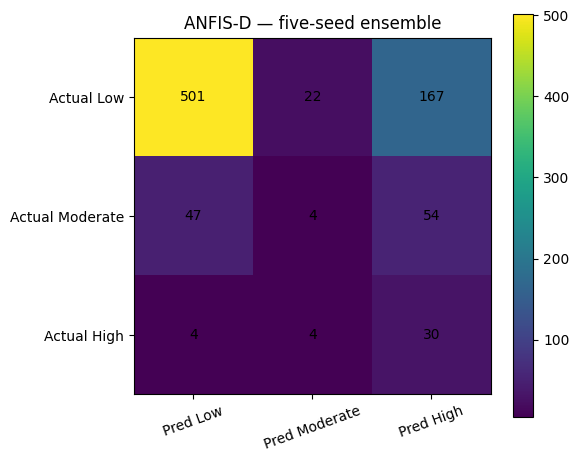

,Experiment,Low correct,Moderate correct,High correct,High→Low,Low→High,Total correct
0,Baseline,508,52,27,2,25,587
1,ANFIS-A,508,53,28,2,34,589
2,ANFIS-B,508,38,29,2,52,575
3,ANFIS-C,470,28,33,2,100,531
4,ANFIS-D,501,4,30,4,167,535


In [11]:
# ============================================================
# Cell 11 — Confusion matrices and key error counts
# ============================================================
key_rows = []

for experiment in (
    EXPERIMENT_ORDER
):
    matrix = (
        confusion_matrices[
            experiment
        ]
    )

    key_rows.append(
        {
            "Experiment": (
                SHORT_NAMES[
                    experiment
                ]
            ),
            "Low correct": int(
                matrix[
                    0,
                    0,
                ]
            ),
            "Moderate correct": int(
                matrix[
                    1,
                    1,
                ]
            ),
            "High correct": int(
                matrix[
                    2,
                    2,
                ]
            ),
            "High→Low": int(
                matrix[
                    2,
                    0,
                ]
            ),
            "Low→High": int(
                matrix[
                    0,
                    2,
                ]
            ),
            "Total correct": int(
                np.trace(
                    matrix
                )
            ),
        }
    )

    plt.figure(
        figsize=(
            6,
            5,
        )
    )

    plt.imshow(
        matrix
    )

    plt.xticks(
        np.arange(3),
        [
            "Pred Low",
            "Pred Moderate",
            "Pred High",
        ],
        rotation=20,
    )

    plt.yticks(
        np.arange(3),
        [
            "Actual Low",
            "Actual Moderate",
            "Actual High",
        ],
    )

    for row_index in range(3):
        for column_index in range(3):
            plt.text(
                column_index,
                row_index,
                int(
                    matrix[
                        row_index,
                        column_index,
                    ]
                ),
                ha="center",
                va="center",
            )

    plt.title(
        (
            SHORT_NAMES[
                experiment
            ]
            + " — five-seed ensemble"
        )
    )

    plt.colorbar()
    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / (
            "confusion_"
            + SHORT_NAMES[
                experiment
            ].lower().replace(
                "-",
                "_",
            )
            + ".png"
        ),
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

key_confusion_table = pd.DataFrame(
    key_rows
)

display(
    key_confusion_table
)

key_confusion_table.to_csv(
    TABLE_DIR
    / "07_KEY_CONFUSION_COUNTS.csv",
    index=False,
)

,Experiment,Class,Precision,Recall,F1
0,Baseline,Low,0.939002,0.736232,0.825345
1,Baseline,Moderate,0.238532,0.495238,0.321981
2,Baseline,High,0.364865,0.710526,0.482143
3,ANFIS-A,Low,0.939002,0.736232,0.825345
4,ANFIS-A,Moderate,0.253589,0.504762,0.337580
5,ANFIS-A,High,0.337349,0.736842,0.462810
6,ANFIS-B,Low,0.939002,0.736232,0.825345
7,ANFIS-B,Moderate,0.217143,0.361905,0.271429
8,ANFIS-B,High,0.247863,0.763158,0.374194
9,ANFIS-C,Low,0.932540,0.681159,0.787270


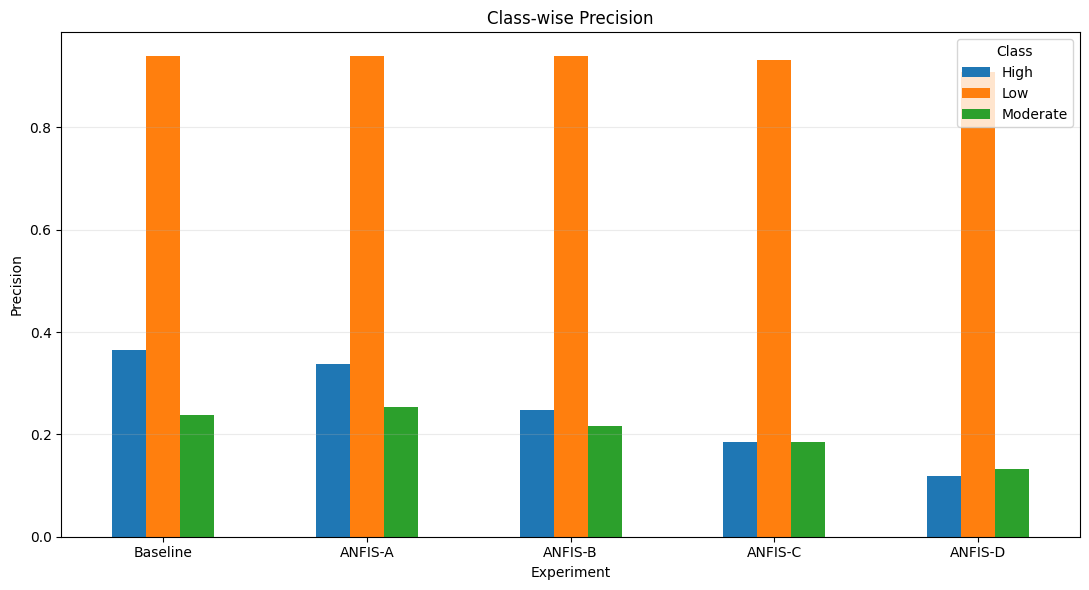

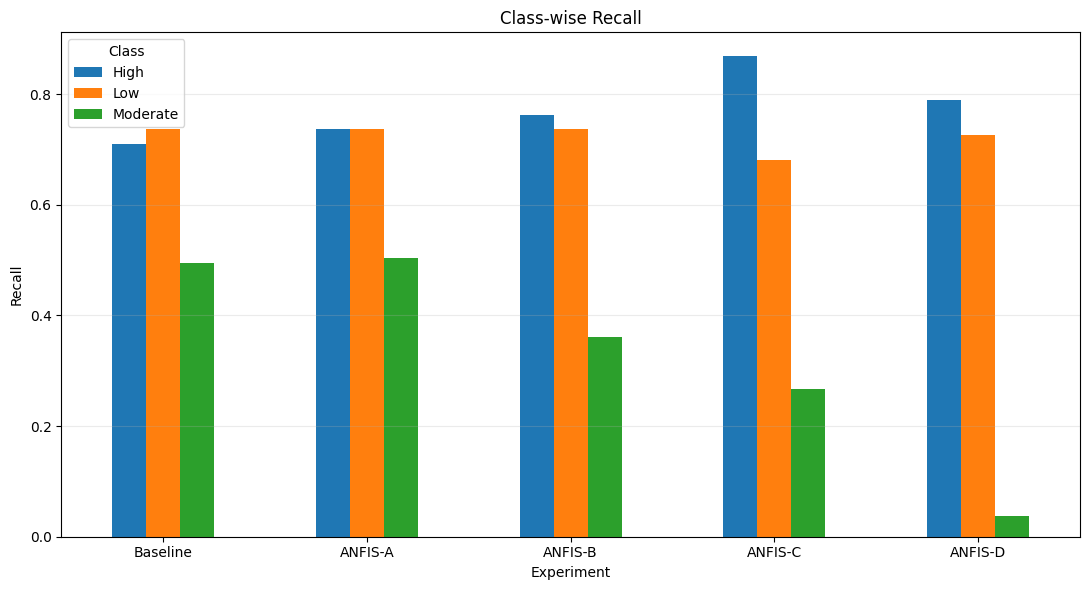

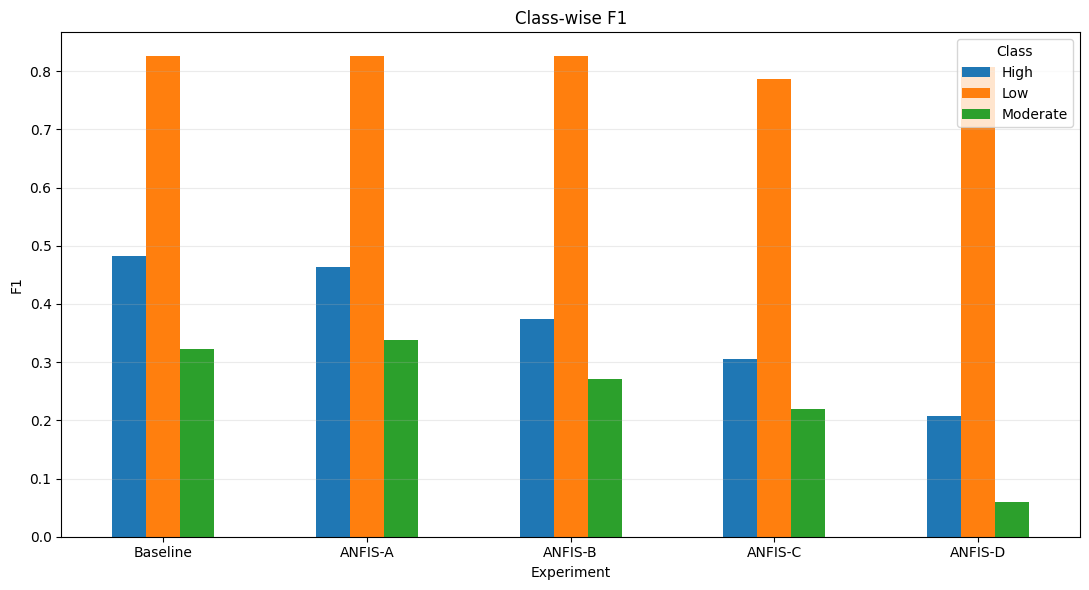

In [12]:
# ============================================================
# Cell 12 — Class-wise metrics and plots
# ============================================================
class_rows = []

for _, row in (
    ensemble_metrics.iterrows()
):
    experiment = (
        row[
            "Experiment"
        ]
    )

    for label in (
        LABEL_ORDER
    ):
        class_rows.append(
            {
                "Experiment": (
                    SHORT_NAMES[
                        experiment
                    ]
                ),
                "Class": (
                    label.title()
                ),
                "Precision": float(
                    row[
                        f"{label}_precision"
                    ]
                ),
                "Recall": float(
                    row[
                        f"{label}_recall"
                    ]
                ),
                "F1": float(
                    row[
                        f"{label}_f1"
                    ]
                ),
            }
        )

classwise_table = pd.DataFrame(
    class_rows
)

display(
    classwise_table.round(6)
)

classwise_table.to_csv(
    TABLE_DIR
    / "08_CLASSWISE_METRICS.csv",
    index=False,
)

for metric in [
    "Precision",
    "Recall",
    "F1",
]:
    pivot = (
        classwise_table.pivot(
            index="Experiment",
            columns="Class",
            values=metric,
        )
        .reindex(
            [
                "Baseline",
                "ANFIS-A",
                "ANFIS-B",
                "ANFIS-C",
                "ANFIS-D",
            ]
        )
    )

    pivot.plot(
        kind="bar",
        figsize=(
            11,
            6,
        ),
        rot=0,
    )

    plt.ylabel(
        metric
    )

    plt.title(
        f"Class-wise {metric}"
    )

    plt.grid(
        axis="y",
        alpha=0.25,
    )

    plt.tight_layout()

    plt.savefig(
        PLOT_DIR
        / (
            "classwise_"
            + metric.lower()
            + ".png"
        ),
        dpi=180,
        bbox_inches="tight",
    )

    plt.show()

,Experiment,Stage,n,threshold,balanced_accuracy,sensitivity,specificity,precision,f1,mcc,roc_auc,average_precision,tn,fp,fn,tp
0,Baseline,Stage 1 Low vs At-risk,833,0.44,0.752731,0.769231,0.736232,0.376712,0.505747,0.399477,0.815405,0.568420,508,182,33,110
1,Baseline,Stage 2 Moderate vs High,143,0.50,0.745739,0.710526,0.780952,0.540000,0.613636,0.455265,0.778947,0.635525,82,23,11,27
2,ANFIS-A,Stage 1 Low vs At-risk,833,0.44,0.752731,0.769231,0.736232,0.376712,0.505747,0.399477,0.815405,0.568420,508,182,33,110
3,ANFIS-A,Stage 2 Moderate vs High,143,0.24,0.744612,0.736842,0.752381,0.518519,0.608696,0.445760,0.738346,0.549228,79,26,10,28
4,ANFIS-B,Stage 1 Low vs At-risk,833,0.44,0.752731,0.769231,0.736232,0.376712,0.505747,0.399477,0.815405,0.568420,508,182,33,110
5,ANFIS-B,Stage 2 Moderate vs High,143,0.32,0.689975,0.789474,0.590476,0.410959,0.540541,0.335739,0.784336,0.563586,62,43,8,30
6,ANFIS-C,Stage 1 Low vs At-risk,833,0.48,0.721699,0.762238,0.681159,0.331307,0.461864,0.342036,0.775910,0.538887,470,220,34,109
7,ANFIS-C,Stage 2 Moderate vs High,143,0.30,0.661654,0.894737,0.428571,0.361702,0.515152,0.300913,0.784336,0.563586,45,60,4,34


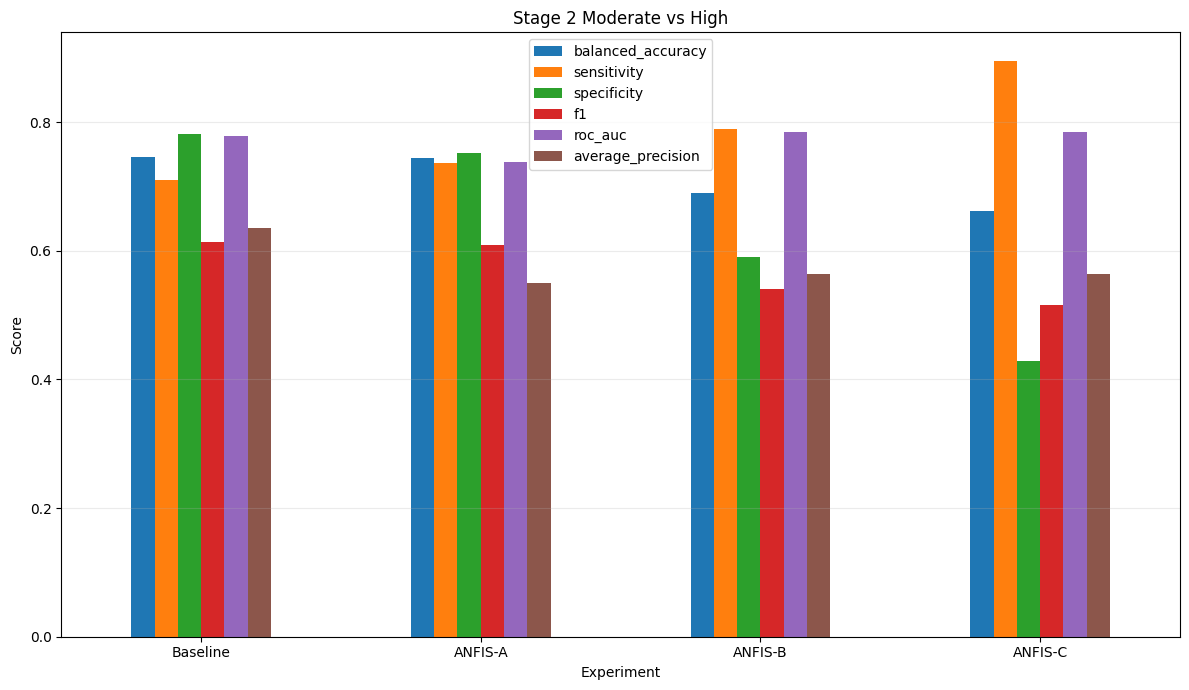

In [13]:
# ============================================================
# Cell 13 — Stage-wise comparison
# ============================================================
stagewise_table = (
    stagewise_metrics.copy()
)

stagewise_table[
    "Experiment"
] = (
    stagewise_table[
        "Experiment"
    ]
    .map(
        SHORT_NAMES
    )
)

stage_columns = [
    "Experiment",
    "Stage",
    "n",
    "threshold",
    "balanced_accuracy",
    "sensitivity",
    "specificity",
    "precision",
    "f1",
    "mcc",
    "roc_auc",
    "average_precision",
    "tn",
    "fp",
    "fn",
    "tp",
]

display(
    stagewise_table[
        stage_columns
    ].round(6)
)

stagewise_table[
    stage_columns
].to_csv(
    TABLE_DIR
    / "09_STAGEWISE_COMPARISON.csv",
    index=False,
)

stage2_plot = (
    stagewise_table.loc[
        stagewise_table[
            "Stage"
        ].str.contains(
            "Stage 2"
        )
    ]
    .set_index(
        "Experiment"
    )[
        [
            "balanced_accuracy",
            "sensitivity",
            "specificity",
            "f1",
            "roc_auc",
            "average_precision",
        ]
    ]
)

stage2_plot.plot(
    kind="bar",
    figsize=(
        12,
        7,
    ),
    rot=0,
)

plt.ylabel(
    "Score"
)

plt.title(
    "Stage 2 Moderate vs High"
)

plt.grid(
    axis="y",
    alpha=0.25,
)

plt.tight_layout()

plt.savefig(
    PLOT_DIR
    / "stage2_comparison.png",
    dpi=180,
    bbox_inches="tight",
)

plt.show()

In [14]:
# ============================================================
# Cell 14 — Bootstrap and McNemar tests
# ============================================================
important_metrics = [
    "accuracy",
    "balanced_accuracy",
    "macro_f1",
    "low_recall",
    "moderate_recall",
    "high_recall",
    "high_to_low",
    "low_to_high",
    "roc_auc_macro",
    "pr_auc_macro",
    "log_loss",
    "brier",
]

bootstrap_table = (
    bootstrap_results.loc[
        bootstrap_results[
            "Metric"
        ].isin(
            important_metrics
        )
    ]
    .copy()
)

bootstrap_table[
    "Candidate"
] = (
    bootstrap_table[
        "Candidate"
    ]
    .map(
        SHORT_NAMES
    )
)

bootstrap_table[
    "CI excludes zero"
] = (
    (
        bootstrap_table[
            "95% CI lower"
        ]
        > 0
    )
    | (
        bootstrap_table[
            "95% CI upper"
        ]
        < 0
    )
)

display(
    bootstrap_table.round(6)
)

bootstrap_table.to_csv(
    TABLE_DIR
    / "10_BOOTSTRAP_RESULTS.csv",
    index=False,
)

mcnemar_table = (
    mcnemar_results.copy()
)

mcnemar_table[
    "Candidate"
] = (
    mcnemar_table[
        "Candidate"
    ]
    .map(
        SHORT_NAMES
    )
)

mcnemar_table[
    "Significant at 0.05"
] = (
    mcnemar_table[
        "Exact McNemar p-value"
    ]
    < 0.05
)

display(
    mcnemar_table
)

mcnemar_table.to_csv(
    TABLE_DIR
    / "11_MCNEMAR_RESULTS.csv",
    index=False,
)

,Candidate,Reference,Metric,Direction,Mean candidate-minus-baseline delta,95% CI lower,95% CI upper,P(candidate better),CI excludes zero
0,ANFIS-A,Baseline RF+GBM,accuracy,Higher is better,0.002450,-0.004802,0.009604,0.686,False
1,ANFIS-A,Baseline RF+GBM,balanced_accuracy,Higher is better,0.012306,-0.009524,0.039033,0.804,False
2,ANFIS-A,Baseline RF+GBM,macro_f1,Higher is better,-0.001014,-0.022275,0.021422,0.459,False
3,ANFIS-A,Baseline RF+GBM,low_recall,Higher is better,0.000000,0.000000,0.000000,0.000,False
4,ANFIS-A,Baseline RF+GBM,moderate_recall,Higher is better,0.009524,-0.047619,0.066667,0.560,False
5,ANFIS-A,Baseline RF+GBM,high_recall,Higher is better,0.027395,0.000000,0.078947,0.651,False
9,ANFIS-A,Baseline RF+GBM,roc_auc_macro,Higher is better,0.032407,0.013603,0.053275,1.000,True
10,ANFIS-A,Baseline RF+GBM,pr_auc_macro,Higher is better,-0.007994,-0.037331,0.019251,0.285,False
11,ANFIS-A,Baseline RF+GBM,brier,Lower is better,0.002493,-0.003733,0.008796,0.216,False
12,ANFIS-A,Baseline RF+GBM,log_loss,Lower is better,-0.008871,-0.018898,0.000883,0.960,False


,Candidate,Reference,Baseline-only correct,Candidate-only correct,Discordant,Exact McNemar p-value,Significant at 0.05
0,ANFIS-A,Baseline RF+GBM,4,6,10,7.539062e-01,False
1,ANFIS-B,Baseline RF+GBM,14,2,16,4.180908e-03,True
2,ANFIS-C,Baseline RF+GBM,74,18,92,3.101450e-09,True
3,ANFIS-D,Baseline RF+GBM,96,44,140,1.314321e-05,True


In [15]:
# ============================================================
# Cell 15 — Expanded supervisor decision table
# ============================================================
ensemble_short = (
    ensemble_metrics.copy()
)

ensemble_short[
    "Short"
] = (
    ensemble_short[
        "Experiment"
    ]
    .map(
        SHORT_NAMES
    )
)

summary_short = (
    seed_summary.copy()
)

summary_short[
    "Short"
] = (
    summary_short[
        "Experiment"
    ]
    .map(
        SHORT_NAMES
    )
)

baseline = (
    ensemble_short.loc[
        ensemble_short[
            "Short"
        ].eq(
            "Baseline"
        )
    ]
    .iloc[0]
)

reverse_short_names = {
    value: key
    for key, value
    in SHORT_NAMES.items()
}

decision_rows = []

for candidate_name in [
    "ANFIS-A",
    "ANFIS-B",
    "ANFIS-C",
    "ANFIS-D",
]:
    candidate = (
        ensemble_short.loc[
            ensemble_short[
                "Short"
            ].eq(
                candidate_name
            )
        ]
        .iloc[0]
    )

    individual = (
        summary_short.loc[
            summary_short[
                "Short"
            ].eq(
                candidate_name
            )
        ]
        .iloc[0]
    )

    full_name = (
        reverse_short_names[
            candidate_name
        ]
    )

    safety_pass = bool(
        selected_configs[
            full_name
        ].get(
            "Safety pass",
            True,
        )
    )

    mcnemar_row = (
        mcnemar_table.loc[
            mcnemar_table[
                "Candidate"
            ].eq(
                candidate_name
            )
        ]
        .iloc[0]
    )

    recommendations = {
        "ANFIS-A": (
            "Promising ensemble candidate; "
            "requires temporal external validation."
        ),
        "ANFIS-B": (
            "Reject: Moderate recall and "
            "Macro-F1 decrease."
        ),
        "ANFIS-C": (
            "Reject: Low and Moderate "
            "performance decrease."
        ),
        "ANFIS-D": (
            "Reject: validation safety failed "
            "and Moderate detection collapsed."
        ),
    }

    decision_rows.append(
        {
            "Experiment": candidate_name,
            "Validation safety pass": (
                safety_pass
            ),
            "Individual BA mean": float(
                individual[
                    "balanced_accuracy mean"
                ]
            ),
            "Individual BA SD": float(
                individual[
                    "balanced_accuracy SD"
                ]
            ),
            "Ensemble BA": float(
                candidate[
                    "balanced_accuracy"
                ]
            ),
            "Delta ensemble BA": float(
                candidate[
                    "balanced_accuracy"
                ]
                - baseline[
                    "balanced_accuracy"
                ]
            ),
            "Delta Macro-F1": float(
                candidate[
                    "macro_f1"
                ]
                - baseline[
                    "macro_f1"
                ]
            ),
            "Delta Low recall": float(
                candidate[
                    "low_recall"
                ]
                - baseline[
                    "low_recall"
                ]
            ),
            "Delta Moderate recall": float(
                candidate[
                    "moderate_recall"
                ]
                - baseline[
                    "moderate_recall"
                ]
            ),
            "Delta High recall": float(
                candidate[
                    "high_recall"
                ]
                - baseline[
                    "high_recall"
                ]
            ),
            "Delta High→Low": int(
                candidate[
                    "high_to_low"
                ]
                - baseline[
                    "high_to_low"
                ]
            ),
            "McNemar p-value": float(
                mcnemar_row[
                    "Exact McNemar p-value"
                ]
            ),
            "Recommendation": (
                recommendations[
                    candidate_name
                ]
            ),
        }
    )

supervisor_decision = (
    pd.DataFrame(
        decision_rows
    )
)

display(
    supervisor_decision.round(6)
)

supervisor_decision.to_csv(
    TABLE_DIR
    / "12_SUPERVISOR_DECISION_TABLE.csv",
    index=False,
)

,Experiment,Validation safety pass,Individual BA mean,Individual BA SD,Ensemble BA,Delta ensemble BA,Delta Macro-F1,Delta Low recall,Delta Moderate recall,Delta High recall,Delta High→Low,McNemar p-value,Recommendation
0,ANFIS-A,True,0.636504,0.021477,0.659279,0.011947,-0.001245,0.000000,0.009524,0.026316,0,0.753906,Promising ensemble candidate; requires tempora...
1,ANFIS-B,True,0.628116,0.042933,0.620432,-0.026901,-0.052834,0.000000,-0.133333,0.052632,0,0.004181,Reject: Moderate recall and Macro-F1 decrease.
2,ANFIS-C,True,0.592844,0.031709,0.605416,-0.041916,-0.105965,-0.055072,-0.228571,0.157895,0,0.000000,Reject: Low and Moderate performance decrease.
3,ANFIS-D,False,0.518410,0.011614,0.517885,-0.129447,-0.185278,-0.010145,-0.457143,0.078947,2,0.000013,Reject: validation safety failed and Moderate ...


In [16]:
# ============================================================
# Cell 16 — English and Bangla supervisor reports
# ============================================================
def pp(
    value,
):
    return (
        f"{value * 100:+.2f} percentage points"
    )


baseline_ensemble = (
    ensemble_short.loc[
        ensemble_short[
            "Short"
        ].eq(
            "Baseline"
        )
    ]
    .iloc[0]
)

anfis_a_ensemble = (
    ensemble_short.loc[
        ensemble_short[
            "Short"
        ].eq(
            "ANFIS-A"
        )
    ]
    .iloc[0]
)

baseline_individual_ba = float(
    summary_short.loc[
        summary_short[
            "Short"
        ].eq(
            "Baseline"
        ),
        "balanced_accuracy mean",
    ].iloc[0]
)

anfis_a_individual_ba = float(
    summary_short.loc[
        summary_short[
            "Short"
        ].eq(
            "ANFIS-A"
        ),
        "balanced_accuracy mean",
    ].iloc[0]
)

anfis_a_mcnemar_p = float(
    mcnemar_table.loc[
        mcnemar_table[
            "Candidate"
        ].eq(
            "ANFIS-A"
        ),
        "Exact McNemar p-value",
    ].iloc[0]
)

seeds_text = ", ".join(
    str(seed)
    for seed in sorted(
        seed_metrics[
            "Seed"
        ].unique()
    )
)

supervisor_summary = f"""
# Supervisor Test-Set Comparison Summary

## Protocol

- Held-out test participants: {int(baseline_ensemble['n'])}
- Training seeds: {seeds_text}
- Configurations and thresholds were frozen before test reporting.
- No test-set retuning was performed.
- Baseline compatibility signature: {baseline_compatibility.get('matched_signature')}

## Main result

The original RF+GBM Model C remained the more stable single-model solution.
Across independent seeds, its mean Balanced Accuracy was
{baseline_individual_ba:.4f}, compared with
{anfis_a_individual_ba:.4f} for ANFIS-A.

ANFIS-A was the only promising five-seed ensemble candidate. Relative to
the baseline ensemble, it changed:

- Accuracy: {pp(float(anfis_a_ensemble['accuracy'] - baseline_ensemble['accuracy']))}
- Balanced Accuracy: {pp(float(anfis_a_ensemble['balanced_accuracy'] - baseline_ensemble['balanced_accuracy']))}
- Macro-F1: {pp(float(anfis_a_ensemble['macro_f1'] - baseline_ensemble['macro_f1']))}
- Low recall: {pp(float(anfis_a_ensemble['low_recall'] - baseline_ensemble['low_recall']))}
- Moderate recall: {pp(float(anfis_a_ensemble['moderate_recall'] - baseline_ensemble['moderate_recall']))}
- High recall: {pp(float(anfis_a_ensemble['high_recall'] - baseline_ensemble['high_recall']))}
- High-to-Low count: {int(anfis_a_ensemble['high_to_low'])} versus {int(baseline_ensemble['high_to_low'])}

Macro-F1 did not improve, individual ANFIS-A models were more seed-sensitive,
and the exact McNemar p-value was {anfis_a_mcnemar_p:.4f}. Therefore, overall
statistically conclusive superiority was not established.

ANFIS-B increased High recall but reduced Moderate recall and Macro-F1.
ANFIS-C reduced Low and Moderate performance.
ANFIS-D failed validation safety and nearly collapsed Moderate detection.

## Recommendation

Retain the original RF+GBM Model C as the primary final model. Carry only
the frozen ANFIS-A five-seed ensemble to NHANES 2017–2018 temporal external
validation. ANFIS-B, ANFIS-C and ANFIS-D should not replace Model C.

## Scientific boundary

The output is a kidney-risk screening proxy, not a confirmed CKD diagnosis.
"""

supervisor_summary = (
    dedent(
        supervisor_summary
    ).strip()
    + "\n"
)

display(
    Markdown(
        supervisor_summary
    )
)

(
    OUTPUT_DIR
    / "SUPERVISOR_TEST_COMPARISON_REPORT.md"
).write_text(
    supervisor_summary,
    encoding="utf-8",
)

bangla_summary = f"""
ANFIS TEST RESULT — BANGLA INTERPRETATION
=========================================

Test N: {int(baseline_ensemble['n'])}
Seeds: {seeds_text}

মূল সিদ্ধান্ত:
বর্তমান RF+GBM Model C single-model হিসেবে বেশি stable।
ANFIS-A শুধু five-seed probability ensemble হিসেবে promising হয়েছে।

ANFIS-A ensemble বনাম baseline:
Accuracy: {pp(float(anfis_a_ensemble['accuracy'] - baseline_ensemble['accuracy']))}
Balanced Accuracy: {pp(float(anfis_a_ensemble['balanced_accuracy'] - baseline_ensemble['balanced_accuracy']))}
Macro-F1: {pp(float(anfis_a_ensemble['macro_f1'] - baseline_ensemble['macro_f1']))}
Low recall: {pp(float(anfis_a_ensemble['low_recall'] - baseline_ensemble['low_recall']))}
Moderate recall: {pp(float(anfis_a_ensemble['moderate_recall'] - baseline_ensemble['moderate_recall']))}
High recall: {pp(float(anfis_a_ensemble['high_recall'] - baseline_ensemble['high_recall']))}
High→Low: {int(anfis_a_ensemble['high_to_low'])} বনাম {int(baseline_ensemble['high_to_low'])}
McNemar p-value: {anfis_a_mcnemar_p:.4f}

Interpretation:
ANFIS-A ensemble Balanced Accuracy, Moderate recall এবং High recall কিছুটা
বাড়িয়েছে, কিন্তু Macro-F1 বাড়ায়নি। Individual ANFIS-A models seed অনুযায়ী
বেশি unstable এবং total-correct difference statistically significant নয়।

ANFIS-B:
High recall বাড়ালেও Moderate recall ও Macro-F1 কমিয়েছে।

ANFIS-C:
High recall বাড়ালেও Low ও Moderate class-এর বড় ক্ষতি করেছে।

ANFIS-D:
Validation safety fail করেছে এবং Moderate class প্রায় detect করতে পারেনি।

Final recommendation:
বর্তমান RF+GBM Model C final রাখুন। Frozen ANFIS-A five-seed ensemble-কে
temporal external-validation candidate হিসেবে এগিয়ে নিন। Test result দেখে
threshold, rules বা resampling আবার পরিবর্তন করবেন না।
"""

bangla_summary = (
    dedent(
        bangla_summary
    ).strip()
    + "\n"
)

(
    OUTPUT_DIR
    / "BANGLA_TEST_RESULT_INTERPRETATION.txt"
).write_text(
    bangla_summary,
    encoding="utf-8",
)

# Supervisor Test-Set Comparison Summary

## Protocol

- Held-out test participants: 833
- Training seeds: 42, 52, 62, 72, 82
- Configurations and thresholds were frozen before test reporting.
- No test-set retuning was performed.
- Baseline compatibility signature: kaggle_numerical_compatible

## Main result

The original RF+GBM Model C remained the more stable single-model solution.
Across independent seeds, its mean Balanced Accuracy was
0.6477, compared with
0.6365 for ANFIS-A.

ANFIS-A was the only promising five-seed ensemble candidate. Relative to
the baseline ensemble, it changed:

- Accuracy: +0.24 percentage points
- Balanced Accuracy: +1.19 percentage points
- Macro-F1: -0.12 percentage points
- Low recall: +0.00 percentage points
- Moderate recall: +0.95 percentage points
- High recall: +2.63 percentage points
- High-to-Low count: 2 versus 2

Macro-F1 did not improve, individual ANFIS-A models were more seed-sensitive,
and the exact McNemar p-value was 0.7539. Therefore, overall
statistically conclusive superiority was not established.

ANFIS-B increased High recall but reduced Moderate recall and Macro-F1.
ANFIS-C reduced Low and Moderate performance.
ANFIS-D failed validation safety and nearly collapsed Moderate detection.

## Recommendation

Retain the original RF+GBM Model C as the primary final model. Carry only
the frozen ANFIS-A five-seed ensemble to NHANES 2017–2018 temporal external
validation. ANFIS-B, ANFIS-C and ANFIS-D should not replace Model C.

## Scientific boundary

The output is a kidney-risk screening proxy, not a confirmed CKD diagnosis.


1248

In [17]:
# ============================================================
# Cell 17 — Manifest and downloadable supervisor ZIP
# ============================================================
def artifact_sha256(
    path,
    chunk_size=1024 * 1024,
):
    digest = hashlib.sha256()

    with open(
        path,
        "rb",
    ) as handle:
        while True:
            chunk = handle.read(
                chunk_size
            )

            if not chunk:
                break

            digest.update(
                chunk
            )

    return digest.hexdigest()


readme = """
ANFIS HELD-OUT TEST COMPARISON REPORT
=====================================

This package is generated from frozen experiment results.
It does not retrain or retune the models.

Main outputs:
- SUPERVISOR_TEST_COMPARISON_REPORT.md
- BANGLA_TEST_RESULT_INTERPRETATION.txt
- tables/03_FIVE_SEED_MEAN_SD.csv
- tables/04_FIVE_SEED_ENSEMBLE_METRICS.csv
- tables/05_ENSEMBLE_DELTAS_VS_BASELINE.csv
- tables/07_KEY_CONFUSION_COUNTS.csv
- tables/09_STAGEWISE_COMPARISON.csv
- tables/10_BOOTSTRAP_RESULTS.csv
- tables/11_MCNEMAR_RESULTS.csv
- tables/12_SUPERVISOR_DECISION_TABLE.csv
"""

(
    OUTPUT_DIR
    / "README_REPORT.txt"
).write_text(
    dedent(
        readme
    ).strip()
    + "\n",
    encoding="utf-8",
)

manifest_rows = []

for path in sorted(
    OUTPUT_DIR.rglob("*")
):
    if path.is_file():
        manifest_rows.append(
            {
                "File": str(
                    path.relative_to(
                        OUTPUT_DIR
                    )
                ),
                "Size bytes": int(
                    path.stat().st_size
                ),
                "SHA256": (
                    artifact_sha256(
                        path
                    )
                ),
            }
        )

report_manifest = pd.DataFrame(
    manifest_rows
)

report_manifest.to_csv(
    OUTPUT_DIR
    / "99_REPORT_MANIFEST.csv",
    index=False,
)

REPORT_ZIP = (
    OUTPUT_DIR
    / "anfis_test_comparison_supervisor_report.zip"
)

if REPORT_ZIP.exists():
    REPORT_ZIP.unlink()

with zipfile.ZipFile(
    REPORT_ZIP,
    "w",
    compression=(
        zipfile.ZIP_DEFLATED
    ),
) as archive:
    for path in sorted(
        OUTPUT_DIR.rglob("*")
    ):
        if (
            path.is_file()
            and path
            != REPORT_ZIP
        ):
            archive.write(
                path,
                arcname=str(
                    path.relative_to(
                        OUTPUT_DIR
                    )
                ),
            )

print(
    "Supervisor report ZIP:",
    REPORT_ZIP,
)

print(
    "ZIP size MB:",
    round(
        REPORT_ZIP.stat().st_size
        / (
            1024
            ** 2
        ),
        2,
    ),
)

display(
    FileLink(
        str(
            REPORT_ZIP
        )
    )
)

Supervisor report ZIP: /kaggle/working/anfis_test_comparison_report/anfis_test_comparison_supervisor_report.zip
ZIP size MB: 0.92


/kaggle/working/anfis_test_comparison_report/anfis_test_comparison_supervisor_report.zip

# Supervisor conclusion

> The original RF–GBM Model C remained the most stable single-model solution. ANFIS-A was the only promising neuro-fuzzy candidate, particularly as a five-seed probability ensemble. However, Macro-F1 did not improve, individual ANFIS-A models were more seed-sensitive, and McNemar testing did not establish statistically significant overall superiority. Model C should remain the primary final model, while the frozen ANFIS-A ensemble should proceed to temporal external validation.

Do not use the held-out test result to retune thresholds, rules or resampling.